# 🏦 Dự án ML: Chấm điểm Rủi ro Tín dụng (Credit Risk Scoring)
**Kiến trúc: XGBoost + LightGBM + Random Forest (Ensemble / Stacking) + SHAP Explainability**

Notebook này được thiết kế chia làm **4 Bước rõ ràng** để bạn chạy trực tiếp trên **Google Colab Pro**:
1. **Bước 1:** Tải dữ liệu thật (32,581 hồ sơ vay) → Khám phá dữ liệu (EDA) → Xử lý dữ liệu lỗi (Outlier) & Chống rò rỉ dữ liệu (Data Leakage) → Tạo đặc trưng tài chính mới (Feature Engineering).
2. **Bước 2:** Huấn luyện Baseline (`Logistic Regression`, `Random Forest`) vs. `XGBoost` (hiểu cách XGBoost sửa lỗi nối tiếp + xử lý mất cân bằng dữ liệu với `scale_pos_weight`).
3. **Bước 3:** Kết hợp **XGBoost + LightGBM + Random Forest** (`Soft Voting` & `Stacking Ensemble`) + **Tối ưu ngưỡng quyết định theo chi phí ngân hàng (Cost-Sensitive Threshold)** + **Giải thích mô hình bằng SHAP**.
4. **Bước 4:** Lưu trọn bộ mô hình & số liệu thực nghiệm (`credit_risk_artifacts.pkl` & `metrics_summary.json`) để tải về máy chạy giao diện Web **Streamlit** và đưa số liệu thật vào `README.md`.

In [4]:
# Cài đặt và kiểm tra thư viện trên Google Colab
!pip install -q xgboost lightgbm shap scikit-learn pandas numpy matplotlib seaborn joblib kagglehub

import warnings
warnings.filterwarnings("ignore")

import os
import glob
import json
import shutil
import joblib
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, confusion_matrix
)
import xgboost as xgb
import lightgbm as lgb
import shap

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Đã nạp đầy đủ thư viện! Phiên bản XGBoost:", xgb.__version__, "| LightGBM:", lgb.__version__)

Đã nạp đầy đủ thư viện! Phiên bản XGBoost: 3.4.1 | LightGBM: 4.6.0


---
## 🔍 BƯỚC 1: Tải dữ liệu thực tế, Khám phá dữ liệu (EDA) & Feature Engineering

### 1.1. Ý nghĩa 12 cột trong bộ dữ liệu `Credit Risk Dataset` (32,581 hồ sơ vay)
| Tên cột | Ý nghĩa thực tế | Kiểu dữ liệu |
|---|---|---|
| `person_age` | Tuổi của người nộp hồ sơ vay | Số (Numeric) |
| `person_income` | Thu nhập hàng năm của người vay (USD) | Số (Numeric) |
| `person_home_ownership` | Tình trạng nhà ở: `RENT` (thuê), `MORTGAGE` (đang trả góp nhà), `OWN` (nhà riêng), `OTHER` | Phân loại (Categorical) |
| `person_emp_length` | Số năm kinh nghiệm làm việc | Số (Numeric - có khuyết) |
| `loan_intent` | Mục đích vay: `EDUCATION`, `MEDICAL`, `VENTURE`, `PERSONAL`, `DEBTCONSOLIDATION` (đảo nợ), `HOMEIMPROVEMENT` | Phân loại (Categorical) |
| `loan_grade` | Hạng tín dụng của khoản vay do hệ thống sơ bộ xếp loại (`A` tốt nhất → `G` rủi ro cao nhất) | Phân loại có thứ tự (`A`–`G`) |
| `loan_amnt` | Số tiền khách muốn vay (USD) | Số (Numeric) |
| `loan_int_rate` | Lãi suất khoản vay (%/năm) | Số (Numeric - có khuyết) |
| `loan_percent_income` | Tỷ lệ Số tiền vay / Thu nhập hàng năm | Số (Numeric) |
| `cb_person_default_on_file` | Lịch sử từng vỡ nợ trước đây trên CIC/tín dụng (`Y` = Có, `N` = Chưa từng) | Phân loại (`Y`/`N`) |
| `cb_person_cred_hist_length` | Số năm đã có lịch sử tín dụng | Số (Numeric) |
| **`loan_status` (Target)** | **Kết quả khoản vay:** `0` = Trả nợ tốt, `1` = **Vỡ nợ / Không trả được nợ (Default)** | Nhãn dự đoán (`0` / `1`) |

In [ ]:
# 1.1. Tải bộ dữ liệu thực tế Credit Risk Dataset (32,581 dòng) - Tự động qua KaggleHub + Mirror dự phòng
CSV_PATH = "credit_risk_dataset.csv"

if not os.path.exists(CSV_PATH):
    # Cách 1: Tải trực tiếp từ Kaggle qua kagglehub (không cần API key trên Google Colab)
    try:
        import kagglehub
        print("Đang tải bộ dữ liệu gốc 'laotse/credit-risk-dataset' qua KaggleHub...")
        dl_dir = kagglehub.dataset_download("laotse/credit-risk-dataset")
        found_csvs = glob.glob(os.path.join(dl_dir, "**", "*.csv"), recursive=True)
        if found_csvs:
            shutil.copy2(found_csvs[0], CSV_PATH)
            print(" Đã tải thành công qua KaggleHub!")
    except Exception as e:
        print(f"KaggleHub không khả dụng ({e}), chuyển sang link dự phòng...")

if not os.path.exists(CSV_PATH):
    # Cách 2: Tải từ các kho lưu trữ GitHub / HuggingFace công khai
    BACKUP_URLS = [
        "https://huggingface.co/datasets/pra240patil/Credit-Risk-Data/resolve/main/credit_risk_dataset.csv",
        "https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/main/credit_risk_dataset.csv",
        "https://raw.githubusercontent.com/LeHongNgoc3820/Project_Credit_Risk/master/credit_risk_dataset.csv",
        "https://raw.githubusercontent.com/issacchan26/CreditRiskPrediction/main/credit_risk_dataset.csv",
        "https://raw.githubusercontent.com/issacchan26/CreditRiskPrediction/master/credit_risk_dataset.csv",
    ]
    for url in BACKUP_URLS:
        try:
            print(f"Đang thử tải từ: {url} ...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=20) as resp, open(CSV_PATH, "wb") as out_f:
                shutil.copyfileobj(resp, out_f)
            if os.path.getsize(CSV_PATH) > 100_000:
                print("Tải thành công từ link dự phòng!")
                break
        except Exception as e:
            if os.path.exists(CSV_PATH):
                os.remove(CSV_PATH)
            print(f"Bỏ qua link ({e})...")

df_raw = pd.read_csv(CSV_PATH)
# Chuẩn hóa tên cột phòng trường hợp bản gốc viết nhầm 'cb_preson_cred_hist_length'
df_raw.rename(columns={"cb_preson_cred_hist_length": "cb_person_cred_hist_length"}, inplace=True)

print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]:,} dòng x {df_raw.shape[1]} cột")
print("\n--- Tỷ lệ nhãn loan_status (0 = Trả tốt, 1 = Vỡ nợ) ---")
print(df_raw["loan_status"].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")
print("\n--- Số lượng giá trị bị khuyết (Missing Values) ---")
print(df_raw.isnull().sum()[df_raw.isnull().sum() > 0])
display(df_raw.head(5))

Kích thước dữ liệu gốc: 32,581 dòng x 12 cột

--- Tỷ lệ nhãn loan_status (0 = Trả tốt, 1 = Vỡ nợ) ---
loan_status
0    78.18%
1    21.82%
Name: proportion, dtype: object

--- Số lượng giá trị bị khuyết (Missing Values) ---
person_emp_length     895
loan_int_rate        3116
dtype: int64


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


=== KIỂM TRA GIÁ TRỊ BẤT THƯỜNG (OUTLIERS) ===
Tuổi lớn nhất trong dữ liệu gốc: 144 tuổi -> Các giá trị > 100 tuổi: [{'person_age': 144, 'person_income': 250000, 'loan_status': 0}, {'person_age': 144, 'person_income': 200000, 'loan_status': 0}, {'person_age': 123, 'person_income': 80004, 'loan_status': 0}, {'person_age': 123, 'person_income': 78000, 'loan_status': 0}, {'person_age': 144, 'person_income': 6000000, 'loan_status': 0}]
Số năm đi làm lớn nhất: 123.0 năm -> Các giá trị > 60 năm: [{'person_age': 22, 'person_emp_length': 123.0, 'loan_status': 1}, {'person_age': 21, 'person_emp_length': 123.0, 'loan_status': 0}]


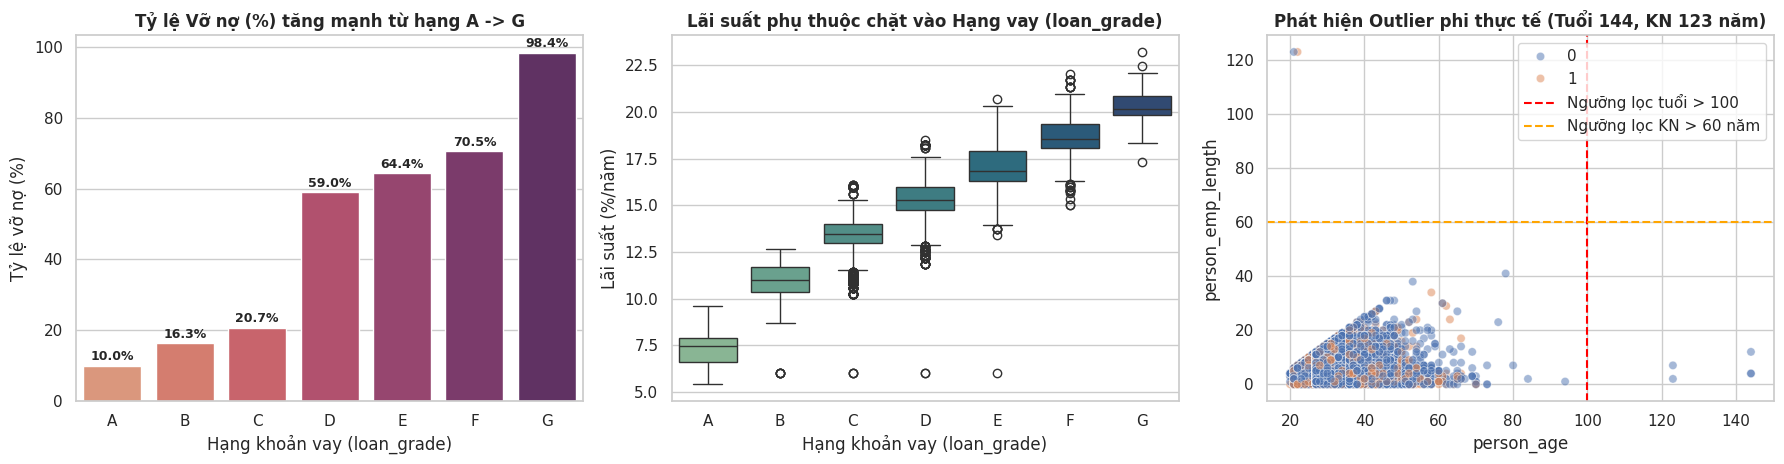

In [3]:
# 1.2. Khám phá dữ liệu (EDA): Phát hiện "bẫy dữ liệu thật" (Outliers & Missing theo nhóm)
print("=== KIỂM TRA GIÁ TRỊ BẤT THƯỜNG (OUTLIERS) ===")
print("Tuổi lớn nhất trong dữ liệu gốc:", df_raw["person_age"].max(), "tuổi -> Các giá trị > 100 tuổi:", df_raw[df_raw["person_age"] > 100][["person_age", "person_income", "loan_status"]].to_dict("records"))
print("Số năm đi làm lớn nhất:", df_raw["person_emp_length"].max(), "năm -> Các giá trị > 60 năm:", df_raw[df_raw["person_emp_length"] > 60][["person_age", "person_emp_length", "loan_status"]].to_dict("records"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Biểu đồ 1: Tỷ lệ vỡ nợ theo Hạng tín dụng (loan_grade A -> G)
grade_order = ["A", "B", "C", "D", "E", "F", "G"]
default_by_grade = df_raw.groupby("loan_grade")["loan_status"].mean().reindex(grade_order) * 100
sns.barplot(x=default_by_grade.index, y=default_by_grade.values, palette="flare", ax=axes[0])
axes[0].set_title("Tỷ lệ Vỡ nợ (%) tăng mạnh từ hạng A -> G", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Tỷ lệ vỡ nợ (%)")
axes[0].set_xlabel("Hạng khoản vay (loan_grade)")
for i, v in enumerate(default_by_grade.values):
    axes[0].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")

# Biểu đồ 2: Lãi suất trung vị theo từng hạng loan_grade (Lý do không được điền khuyết bằng trung bình chung!)
sns.boxplot(data=df_raw, x="loan_grade", y="loan_int_rate", order=grade_order, palette="crest", ax=axes[1])
axes[1].set_title("Lãi suất phụ thuộc chặt vào Hạng vay (loan_grade)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Hạng khoản vay (loan_grade)")
axes[1].set_ylabel("Lãi suất (%/năm)")

# Biểu đồ 3: Phát hiện Outlier ở Tuổi vs. Số năm đi làm
sns.scatterplot(data=df_raw, x="person_age", y="person_emp_length", hue="loan_status", alpha=0.5, ax=axes[2])
axes[2].axvline(100, color="red", linestyle="--", label="Ngưỡng lọc tuổi > 100")
axes[2].axhline(60, color="orange", linestyle="--", label="Ngưỡng lọc KN > 60 năm")
axes[2].set_title("Phát hiện Outlier phi thực tế (Tuổi 144, KN 123 năm)", fontsize=12, fontweight="bold")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

In [6]:
# 1.3. Làm sạch dữ liệu, Chia tập Train/Val/Test & Chống rò rỉ dữ liệu (Zero Data Leakage)
# Bước A: Loại bỏ bản ghi trùng lặp và các dòng nhập sai phi thực tế (tuổi > 100 hoặc số năm đi làm > 60 hoặc năm đi làm > tuổi - 14)
df_clean = df_raw.drop_duplicates().copy()
before_rows = len(df_clean)
df_clean = df_clean[
    (df_clean["person_age"] <= 100)
    & ((df_clean["person_emp_length"].isna()) | (df_clean["person_emp_length"] <= 60))
    & ((df_clean["person_emp_length"].isna()) | (df_clean["person_emp_length"] <= df_clean["person_age"] - 14))
].reset_index(drop=True)
print(f"Đã lọc bỏ {before_rows - len(df_clean)} bản ghi lỗi/outlier phi thực tế. Còn lại: {len(df_clean):,} hồ sơ sạch.")

# Bước B: Chia tập Train (70%) - Validation (15%) - Test (15%) TRƯỚC KHI tính toán thống kê điền khuyết!
X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print(f"Kích thước tập: Train = {len(X_train):,} | Val = {len(X_val):,} | Test = {len(X_test):,}")

# Bước C: Điền giá trị khuyết (Imputation) CHỈ học từ tập Train để không rò rỉ dữ liệu (No Data Leakage)
grade_int_rate_median = X_train.groupby("loan_grade")["loan_int_rate"].median().to_dict()
global_int_rate_median = float(X_train["loan_int_rate"].median())
emp_length_median = float(X_train["person_emp_length"].median())

print("Median lãi suất theo từng hạng vay (học từ tập Train):", {k: round(v, 2) for k, v in grade_int_rate_median.items()})

def apply_imputation_and_feature_engineering(df_part: pd.DataFrame) -> pd.DataFrame:
    d = df_part.copy()
    # 1. Cờ đánh dấu hồ sơ bị thiếu thông tin
    d["int_rate_missing"] = d["loan_int_rate"].isna().astype(int)
    d["emp_length_missing"] = d["person_emp_length"].isna().astype(int)

    # 2. Điền khuyết loan_int_rate theo nhóm loan_grade
    d["loan_int_rate"] = d["loan_int_rate"].fillna(d["loan_grade"].map(grade_int_rate_median)).fillna(global_int_rate_median)
    d["person_emp_length"] = d["person_emp_length"].fillna(emp_length_median)

    # 3. Tạo các đặc trưng tài chính chuyên sâu (Domain Feature Engineering):
    d["true_loan_to_income"] = d["loan_amnt"] / (d["person_income"] + 1.0)
    d["loan_percent_discrepancy"] = (d["loan_percent_income"] - d["true_loan_to_income"]).abs()

    d["annual_interest_amount"] = d["loan_amnt"] * (d["loan_int_rate"] / 100.0)
    d["interest_to_income_ratio"] = d["annual_interest_amount"] / (d["person_income"] + 1.0)

    d["income_per_emp_year"] = d["person_income"] / (d["person_emp_length"] + 1.0)
    d["cred_hist_to_adult_age"] = d["cb_person_cred_hist_length"] / np.maximum(d["person_age"] - 18.0, 1.0)

    grade_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}
    d["loan_grade_num"] = d["loan_grade"].map(grade_map).fillna(4).astype(int)
    d["prior_default_flag"] = (d["cb_person_default_on_file"] == "Y").astype(int)
    return d

X_train_fe = apply_imputation_and_feature_engineering(X_train)
X_val_fe = apply_imputation_and_feature_engineering(X_val)
X_test_fe = apply_imputation_and_feature_engineering(X_test)

# One-Hot Encoding cho 2 cột phân loại không thứ tự (person_home_ownership, loan_intent)
cat_cols = ["person_home_ownership", "loan_intent"]
drop_raw_cols = ["loan_grade", "cb_person_default_on_file"] + cat_cols
num_cols = [c for c in X_train_fe.columns if c not in drop_raw_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

X_train_mat = preprocessor.fit_transform(X_train_fe)
X_val_mat = preprocessor.transform(X_val_fe)
X_test_mat = preprocessor.transform(X_test_fe)

cat_feature_names = list(preprocessor.named_transformers_["cat"].get_feature_names_out(cat_cols))
feature_names = num_cols + cat_feature_names

X_train_df = pd.DataFrame(X_train_mat, columns=feature_names)
X_val_df = pd.DataFrame(X_val_mat, columns=feature_names)
X_test_df = pd.DataFrame(X_test_mat, columns=feature_names)

print(f" Hoàn tất Bước 1! Số lượng đặc trưng sau Feature Engineering: {len(feature_names)} cột.")
print("Danh sách các đặc trưng:", feature_names)

Đã lọc bỏ 7 bản ghi lỗi/outlier phi thực tế. Còn lại: 32,409 hồ sơ sạch.
Kích thước tập: Train = 22,686 | Val = 4,861 | Test = 4,862
Median lãi suất theo từng hạng vay (học từ tập Train): {'A': 7.49, 'B': 10.99, 'C': 13.49, 'D': 15.31, 'E': 16.77, 'F': 18.53, 'G': 20.11}
 Hoàn tất Bước 1! Số lượng đặc trưng sau Feature Engineering: 27 cột.
Danh sách các đặc trưng: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'int_rate_missing', 'emp_length_missing', 'true_loan_to_income', 'loan_percent_discrepancy', 'annual_interest_amount', 'interest_to_income_ratio', 'income_per_emp_year', 'cred_hist_to_adult_age', 'loan_grade_num', 'prior_default_flag', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', '

---
## 🚀 BƯỚC 2: Huấn luyện Baseline vs. XGBoost (Hiểu bản chất XGBoost & Mất cân bằng dữ liệu)

### Tại sao XGBoost lại mạnh vượt trội trên dữ liệu bảng (Tabular Data)?
1. **Logistic Regression (Tuyến tính):** Chỉ kẻ được 1 đường thẳng phân chia, không tự bắt được quan hệ phi tuyến kiểu *"Thu nhập cao NHƯNG vay mục đích Đảo nợ + lãi suất > 15% thì vẫn vỡ nợ"*.
2. **Random Forest (Bagging — Song song):** Xây hàng trăm cây quyết định **độc lập** rồi lấy biểu quyết số đông. Giảm phương sai (variance) tốt nhưng các cây không rút kinh nghiệm từ lỗi của nhau.
3. **XGBoost (Extreme Gradient Boosting — Nối tiếp):** Xây từng cây **nối tiếp nhau**: Cây thứ 2 tập trung học để **sửa những hồ sơ mà Cây thứ 1 dự đoán sai** (dựa trên đạo hàm bậc 1 & bậc 2 của hàm mất mát + phạt chống học vẹt L1/L2 Regularization).
4. **Cơ chế `scale_pos_weight` cho dữ liệu mất cân bằng:** Trong bộ dữ liệu có ~78% khách tốt và ~22% khách vỡ nợ (`tỷ lệ ~3.5 : 1`). Khi bật `scale_pos_weight`, mỗi khách vỡ nợ bị bỏ sót sẽ bị phạt nặng hơn, giúp tăng mạnh độ nhạy (`Recall`).

In [7]:
# 2.1. Hàm chấm điểm chuẩn hóa trên cả Validation và Test
def evaluate_probs(name, val_probs, y_v, test_probs, y_te, threshold=0.50):
    test_preds = (test_probs >= threshold).astype(int)
    return {
        "Model": name,
        "Val_ROC_AUC": round(float(roc_auc_score(y_v, val_probs)), 4),
        "Test_ROC_AUC": round(float(roc_auc_score(y_te, test_probs)), 4),
        "Test_PR_AUC": round(float(average_precision_score(y_te, test_probs)), 4),
        "Test_F1": round(float(f1_score(y_te, test_preds)), 4),
        "Test_Precision": round(float(precision_score(y_te, test_preds)), 4),
        "Test_Recall": round(float(recall_score(y_te, test_preds)), 4),
    }

results = []

# 1. Baseline 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
lr_model.fit(X_train_df, y_train)
results.append(evaluate_probs(
    "1. Logistic Regression (Baseline)",
    lr_model.predict_proba(X_val_df)[:, 1], y_val,
    lr_model.predict_proba(X_test_df)[:, 1], y_test
))

# 2. Baseline 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=14, min_samples_leaf=4,
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
)
rf_model.fit(X_train_df, y_train)
results.append(evaluate_probs(
    "2. Random Forest",
    rf_model.predict_proba(X_val_df)[:, 1], y_val,
    rf_model.predict_proba(X_test_df)[:, 1], y_test
))

# 3. XGBoost Mặc định (Chưa tinh chỉnh & chưa cân bằng nhãn)
xgb_default = xgb.XGBClassifier(
    n_estimators=300, random_state=SEED, eval_metric="auc", n_jobs=-1
)
xgb_default.fit(X_train_df, y_train, eval_set=[(X_val_df, y_val)], verbose=False)
results.append(evaluate_probs(
    "3. XGBoost (Default)",
    xgb_default.predict_proba(X_val_df)[:, 1], y_val,
    xgb_default.predict_proba(X_test_df)[:, 1], y_test
))

# 4. XGBoost Tối ưu (Regularized + Early Stopping + Cân bằng trọng số)
xgb_tuned = xgb.XGBClassifier(
    n_estimators=800,
    learning_rate=0.035,
    max_depth=6,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.5,         # L1 Regularization chống overfitting
    reg_lambda=2.0,        # L2 Regularization
    scale_pos_weight=1.5,  # Tăng độ nhạy phát hiện khách vỡ nợ mà không làm tụt Precision
    random_state=SEED,
    eval_metric="auc",
    early_stopping_rounds=40,
    n_jobs=-1,
)
xgb_tuned.fit(X_train_df, y_train, eval_set=[(X_val_df, y_val)], verbose=False)
results.append(evaluate_probs(
    "4. XGBoost (Tuned + Regularized)",
    xgb_tuned.predict_proba(X_val_df)[:, 1], y_val,
    xgb_tuned.predict_proba(X_test_df)[:, 1], y_test
))

best_n_trees = int(getattr(xgb_tuned, "best_iteration", 400) or 400)
print(f"✅ XGBoost Tuned dừng tối ưu ở cây thứ (best_iteration): {best_n_trees}")
display(pd.DataFrame(results))

✅ XGBoost Tuned dừng tối ưu ở cây thứ (best_iteration): 627


,Model,Val_ROC_AUC,Test_ROC_AUC,Test_PR_AUC,Test_F1,Test_Precision,Test_Recall
0,1. Logistic Regression (Baseline),0.8889,0.8688,0.7206,0.6250,0.5207,0.7817
1,2. Random Forest,0.9427,0.9359,0.8885,0.8219,0.9108,0.7488
2,3. XGBoost (Default),0.9555,0.9510,0.9130,0.8464,0.9402,0.7695
3,4. XGBoost (Tuned + Regularized),0.9558,0.9546,0.9143,0.8384,0.9404,0.7563


---
## 🤝 BƯỚC 3: Kết hợp "Bộ ba" XGBoost + LightGBM + Random Forest (Ensemble) & Giải thích SHAP

### 3.1. Tại sao kết hợp `XGBoost + LightGBM + Random Forest` lại tốt hơn 1 model đơn lẻ?
- **XGBoost** phát triển cây theo tầng (*depth-wise*), kiểm soát overfitting rất chặt.
- **LightGBM** phát triển cây theo nhánh có độ lợi lớn nhất (*leaf-wise*), bắt các cụm tương tác cục bộ cực nhạy.
- **Random Forest** lấy trung bình hàng trăm cây độc lập (*bagging*), giúp làm mượt phương sai.
- Khi kết hợp xác suất của cả 3 mô hình qua **Weighted Soft Voting** hoặc **Out-of-Fold Stacking (Meta-Learner)**, sai số riêng lẻ của từng thuật toán tự triệt tiêu lẫn nhau!

In [8]:
# 3.1. Huấn luyện LightGBM + Kết hợp Soft Voting & Out-of-Fold Stacking Ensemble
# (Viết tường minh bằng xác suất để tương thích 100% mọi phiên bản scikit-learn 1.6+ và dễ hiểu bản chất!)
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.035,
    num_leaves=31,
    max_depth=6,
    colsample_bytree=0.85,
    subsample=0.85,
    reg_alpha=0.5,
    reg_lambda=2.0,
    class_weight={0: 1.0, 1: 1.5},
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)
lgb_model.fit(X_train_df, y_train)

val_p_xgb = xgb_tuned.predict_proba(X_val_df)[:, 1]
test_p_xgb = xgb_tuned.predict_proba(X_test_df)[:, 1]

val_p_lgb = lgb_model.predict_proba(X_val_df)[:, 1]
test_p_lgb = lgb_model.predict_proba(X_test_df)[:, 1]

val_p_rf = rf_model.predict_proba(X_val_df)[:, 1]
test_p_rf = rf_model.predict_proba(X_test_df)[:, 1]

results.append(evaluate_probs("5. LightGBM (Tuned)", val_p_lgb, y_val, test_p_lgb, y_test))

# Mô hình kết hợp 1: Weighted Soft Voting (45% XGBoost + 35% LightGBM + 20% Random Forest)
WEIGHTS = (0.45, 0.35, 0.20)
val_probs_voting = WEIGHTS[0] * val_p_xgb + WEIGHTS[1] * val_p_lgb + WEIGHTS[2] * val_p_rf
test_probs_voting = WEIGHTS[0] * test_p_xgb + WEIGHTS[1] * test_p_lgb + WEIGHTS[2] * test_p_rf
results.append(evaluate_probs("6. Hybrid Soft-Voting (XGB + LGB + RF)", val_probs_voting, y_val, test_probs_voting, y_test))

# Mô hình kết hợp 2: Stacking Meta-Learner (Logistic Regression học trọng số tối ưu trên xác suất của 3 model)
val_meta_X = np.column_stack([val_p_xgb, val_p_lgb, val_p_rf])
test_meta_X = np.column_stack([test_p_xgb, test_p_lgb, test_p_rf])

meta_learner = LogisticRegression(random_state=SEED)
meta_learner.fit(val_meta_X, y_val)
val_probs_stacking = meta_learner.predict_proba(val_meta_X)[:, 1]
test_probs_stacking = meta_learner.predict_proba(test_meta_X)[:, 1]
results.append(evaluate_probs("7. Hybrid Stacking (XGB + LGB + RF -> Meta LR)", val_probs_stacking, y_val, test_probs_stacking, y_test))

results_df = pd.DataFrame(results).sort_values(by="Test_ROC_AUC", ascending=False).reset_index(drop=True)
print("=== BẢNG XẾP HẠNG CÁC MÔ HÌNH TRÊN TẬP TEST ĐỘC LẬP ===")
display(results_df)

=== BẢNG XẾP HẠNG CÁC MÔ HÌNH TRÊN TẬP TEST ĐỘC LẬP ===


,Model,Val_ROC_AUC,Test_ROC_AUC,Test_PR_AUC,Test_F1,Test_Precision,Test_Recall
0,4. XGBoost (Tuned + Regularized),0.9558,0.9546,0.9143,0.8384,0.9404,0.7563
1,7. Hybrid Stacking (XGB + LGB + RF -> Meta LR),0.9556,0.9534,0.9120,0.8389,0.9373,0.7592
2,6. Hybrid Soft-Voting (XGB + LGB + RF),0.9551,0.9528,0.9113,0.8400,0.9458,0.7554
3,5. LightGBM (Tuned),0.9556,0.9524,0.9103,0.8373,0.9434,0.7526
4,3. XGBoost (Default),0.9555,0.9510,0.9130,0.8464,0.9402,0.7695
5,2. Random Forest,0.9427,0.9359,0.8885,0.8219,0.9108,0.7488
6,1. Logistic Regression (Baseline),0.8889,0.8688,0.7206,0.6250,0.5207,0.7817


🎯 Ngưỡng tối ưu F1-Score trên Val: 0.49
💰 Ngưỡng tối ưu Chi phí Ngân hàng (FN=$5k, FP=$1k) trên Val: 0.24
   -> Trên tập Test (4,862 hồ sơ): Ngưỡng 0.50 bắt được 803/1063 ca vỡ nợ (Recall=75.5%), thiệt hại ước tính $1,346,000
   -> Ngưỡng tối ưu 0.24 bắt được 913/1063 ca vỡ nợ (Recall=85.9%), tiết kiệm được $226,000 trên tập Test!


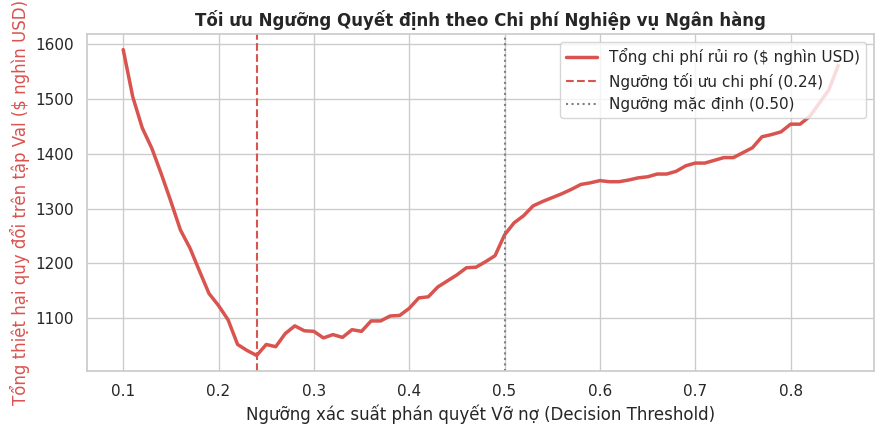

In [9]:
# 3.2. Tối ưu Ngưỡng quyết định theo Bài toán Kinh doanh Ngân hàng (Business Cost Optimization)
COST_FN = 5000  # Bỏ lọt 1 khách vỡ nợ: thiệt hại trung bình $5,000
COST_FP = 1000  # Từ chối nhầm 1 khách tốt: mất chi phí cơ hội $1,000

val_probs_ens = val_probs_voting
test_probs_ens = test_probs_voting
thresholds = np.linspace(0.10, 0.85, 76)
costs = []
f1s = []

for th in thresholds:
    preds = (val_probs_ens >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    total_cost = fn * COST_FN + fp * COST_FP
    costs.append(total_cost)
    f1s.append(f1_score(y_val, preds))

best_cost_idx = int(np.argmin(costs))
best_cost_threshold = float(round(thresholds[best_cost_idx], 2))
best_f1_idx = int(np.argmax(f1s))
best_f1_threshold = float(round(thresholds[best_f1_idx], 2))

tn_50, fp_50, fn_50, tp_50 = confusion_matrix(y_test, (test_probs_ens >= 0.50).astype(int)).ravel()
cost_50 = fn_50 * COST_FN + fp_50 * COST_FP

tn_opt, fp_opt, fn_opt, tp_opt = confusion_matrix(y_test, (test_probs_ens >= best_cost_threshold).astype(int)).ravel()
cost_opt = fn_opt * COST_FN + fp_opt * COST_FP
saved_money = cost_50 - cost_opt

print(f"🎯 Ngưỡng tối ưu F1-Score trên Val: {best_f1_threshold:.2f}")
print(f"💰 Ngưỡng tối ưu Chi phí Ngân hàng (FN=$5k, FP=$1k) trên Val: {best_cost_threshold:.2f}")
print(f"   -> Trên tập Test ({len(y_test):,} hồ sơ): Ngưỡng 0.50 bắt được {tp_50}/{tp_50+fn_50} ca vỡ nợ (Recall={tp_50/(tp_50+fn_50):.1%}), thiệt hại ước tính ${cost_50:,.0f}")
print(f"   -> Ngưỡng tối ưu {best_cost_threshold:.2f} bắt được {tp_opt}/{tp_opt+fn_opt} ca vỡ nợ (Recall={tp_opt/(tp_opt+fn_opt):.1%}), tiết kiệm được ${saved_money:,.0f} trên tập Test!")

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(thresholds, np.array(costs) / 1000, color="#D9534F", linewidth=2.5, label="Tổng chi phí rủi ro ($ nghìn USD)")
ax1.axvline(best_cost_threshold, color="#D9534F", linestyle="--", label=f"Ngưỡng tối ưu chi phí ({best_cost_threshold:.2f})")
ax1.axvline(0.50, color="gray", linestyle=":", label="Ngưỡng mặc định (0.50)")
ax1.set_xlabel("Ngưỡng xác suất phán quyết Vỡ nợ (Decision Threshold)")
ax1.set_ylabel("Tổng thiệt hại quy đổi trên tập Val ($ nghìn USD)", color="#D9534F")
ax1.set_title("Tối ưu Ngưỡng Quyết định theo Chi phí Nghiệp vụ Ngân hàng", fontsize=12, fontweight="bold")
ax1.legend(loc="upper right")
plt.tight_layout()
plt.savefig("threshold_optimization.png", dpi=150)
plt.show()

=== 1. BIỂU ĐỒ SHAP TOÀN CỤC: YẾU TỐ NÀO QUYẾT ĐỊNH RỦI RO VỠ NỢ NHIỀU NHẤT? ===


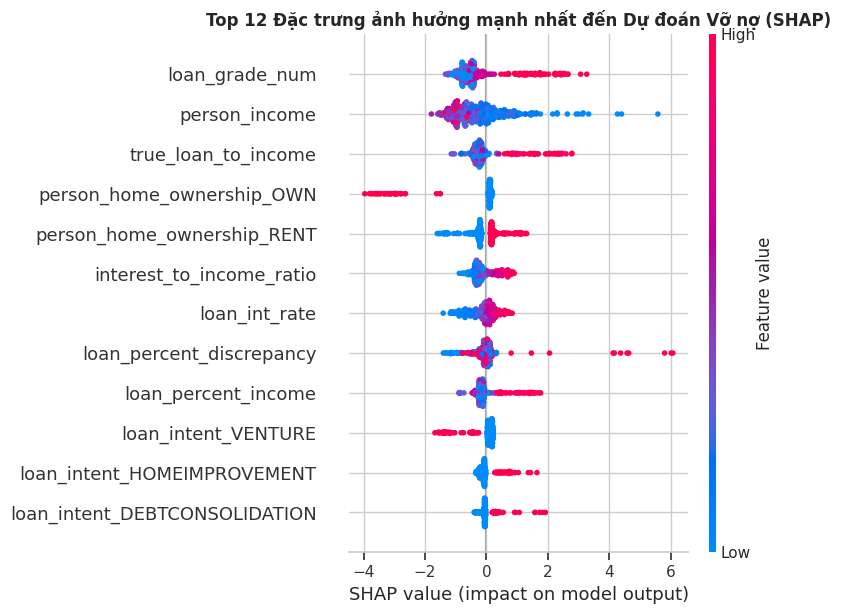


=== 2. GIẢI THÍCH CHI TIẾT HỒ SƠ KHÁCH HÀNG #11 (Xác suất vỡ nợ dự đoán: 94.2%) ===


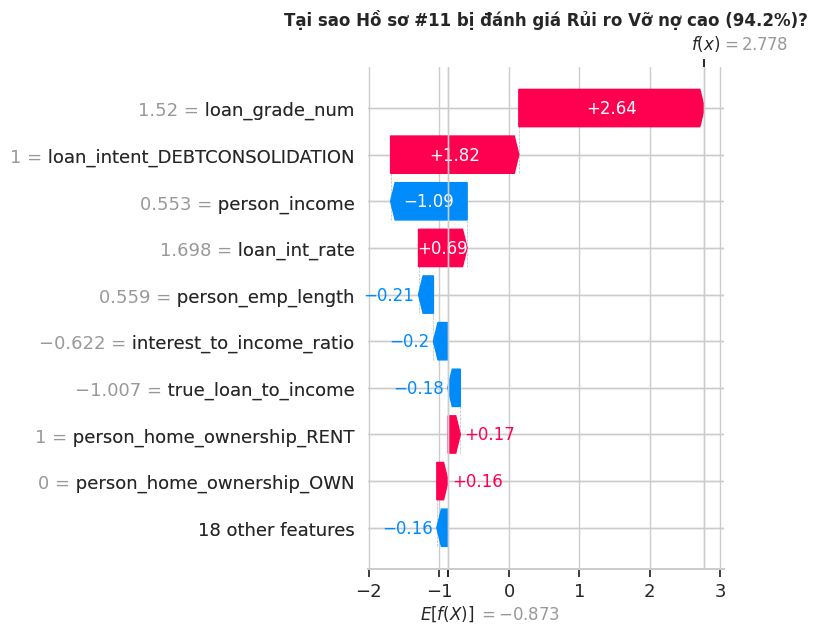

In [10]:
# 3.3. Giải thích Mô hình Minh bạch bằng SHAP (Explainable AI - XAI)
sample_shap_df = X_test_df.iloc[:400].copy()
try:
    explainer = shap.TreeExplainer(xgb_tuned)
    shap_values = explainer(sample_shap_df)
except Exception:
    # Dự phòng tương thích nếu phiên bản SHAP/XGBoost mới xung đột định dạng base_score
    explainer = shap.TreeExplainer(lgb_model)
    shap_values = explainer(sample_shap_df)
    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 1]

print("=== 1. BIỂU ĐỒ SHAP TOÀN CỤC: YẾU TỐ NÀO QUYẾT ĐỊNH RỦI RO VỠ NỢ NHIỀU NHẤT? ===")
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_shap_df, max_display=12, show=False)
plt.title("Top 12 Đặc trưng ảnh hưởng mạnh nhất đến Dự đoán Vỡ nợ (SHAP)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

high_risk_indices = np.where((test_probs_ens[:400] > 0.80) & (y_test.iloc[:400].values == 1))[0]
idx_demo = int(high_risk_indices[0]) if len(high_risk_indices) > 0 else 0
print(f"\n=== 2. GIẢI THÍCH CHI TIẾT HỒ SƠ KHÁCH HÀNG #{idx_demo} (Xác suất vỡ nợ dự đoán: {test_probs_ens[idx_demo]:.1%}) ===")
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[idx_demo], max_display=10, show=False)
plt.title(f"Tại sao Hồ sơ #{idx_demo} bị đánh giá Rủi ro Vỡ nợ cao ({test_probs_ens[idx_demo]:.1%})?", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("shap_waterfall_single.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# 4. Đóng gói toàn bộ Artifacts & Báo cáo số liệu thật để tải về chạy Web Streamlit
artifacts = {
    "preprocessor": preprocessor,
    "feature_names": feature_names,
    "num_cols": num_cols,
    "cat_cols": cat_cols,
    "grade_int_rate_median": grade_int_rate_median,
    "global_int_rate_median": global_int_rate_median,
    "emp_length_median": emp_length_median,
    "xgb_model": xgb_tuned,
    "lgb_model": lgb_model,
    "rf_model": rf_model,
    "voting_weights": WEIGHTS,
    "meta_learner": meta_learner,
    "best_cost_threshold": best_cost_threshold,
    "best_f1_threshold": best_f1_threshold,
    "results_table": results_df.to_dict(orient="records"),
}

joblib.dump(artifacts, "credit_risk_artifacts.pkl")

summary_report = {
    "dataset_rows_raw": int(len(df_raw)),
    "dataset_rows_clean": int(len(df_clean)),
    "outliers_removed": int(before_rows - len(df_clean)),
    "default_rate_pct": round(float(y.mean() * 100), 2),
    "num_features_engineered": int(len(feature_names)),
    "xgb_best_iteration": int(best_n_trees),
    "best_f1_threshold": best_f1_threshold,
    "best_cost_threshold": best_cost_threshold,
    "cost_saved_on_test_usd": int(saved_money),
    "models_benchmark": results_df.to_dict(orient="records"),
}

with open("metrics_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_report, f, indent=2, ensure_ascii=False)

print("Đã lưu thành công:")
print("  1. credit_risk_artifacts.pkl")
print("  2. metrics_summary.json")
print("  3. Các ảnh biểu đồ: eda_overview.png, threshold_optimization.png, shap_summary.png, shap_waterfall_single.png")

Đã lưu thành công:
  1. credit_risk_artifacts.pkl
  2. metrics_summary.json
  3. Các ảnh biểu đồ: eda_overview.png, threshold_optimization.png, shap_summary.png, shap_waterfall_single.png
